In [1]:
# Loading the dataset using pandas

import pandas as pd

df = pd.read_csv('customer_shopping_behavior.csv')

In [2]:
df.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   str    
 3   Item Purchased          3900 non-null   str    
 4   Category                3900 non-null   str    
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   str    
 7   Size                    3900 non-null   str    
 8   Color                   3900 non-null   str    
 9   Season                  3900 non-null   str    
 10  Review Rating           3863 non-null   float64
 11  Subscription Status     3900 non-null   str    
 12  Shipping Type           3900 non-null   str    
 13  Discount Applied        3900 non-null   str    
 14  Promo Code Used         3900 non-null   str    
 15

In [4]:
# Summary statistics using .describe()
df.describe(include='all')

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
count,3900.000000,3900.000000,3900,3900,3900,3900.000000,3900,3900,3900,3900,3863.000000,3900,3900,3900,3900,3900.000000,3900,3900
unique,NaN,NaN,2,25,4,NaN,50,4,25,4,NaN,2,6,2,2,NaN,6,7
top,NaN,NaN,Male,Blouse,Clothing,NaN,Montana,M,Olive,Spring,NaN,No,Free Shipping,No,No,NaN,PayPal,Every 3 Months
freq,NaN,NaN,2652,171,1737,NaN,96,1755,177,999,NaN,2847,675,2223,2223,NaN,677,584
mean,1950.500000,44.068462,NaN,NaN,NaN,59.764359,NaN,NaN,NaN,NaN,3.750065,NaN,NaN,NaN,NaN,25.351538,NaN,NaN
std,1125.977353,15.207589,NaN,NaN,NaN,23.685392,NaN,NaN,NaN,NaN,0.716983,NaN,NaN,NaN,NaN,14.447125,NaN,NaN
min,1.000000,18.000000,NaN,NaN,NaN,20.000000,NaN,NaN,NaN,NaN,2.500000,NaN,NaN,NaN,NaN,1.000000,NaN,NaN
25%,975.750000,31.000000,NaN,NaN,NaN,39.000000,NaN,NaN,NaN,NaN,3.100000,NaN,NaN,NaN,NaN,13.000000,NaN,NaN
50%,1950.500000,44.000000,NaN,NaN,NaN,60.000000,NaN,NaN,NaN,NaN,3.800000,NaN,NaN,NaN,NaN,25.000000,NaN,NaN
75%,2925.250000,57.000000,NaN,NaN,NaN,81.000000,NaN,NaN,NaN,NaN,4.400000,NaN,NaN,NaN,NaN,38.000000,NaN,NaN


In [5]:
# Checking if missing data or null values are present in the dataset

df.isnull().sum()

Customer ID                0
Age                        0
Gender                     0
Item Purchased             0
Category                   0
Purchase Amount (USD)      0
Location                   0
Size                       0
Color                      0
Season                     0
Review Rating             37
Subscription Status        0
Shipping Type              0
Discount Applied           0
Promo Code Used            0
Previous Purchases         0
Payment Method             0
Frequency of Purchases     0
dtype: int64

In [6]:
# Imputing missing values in Review Rating column with the median rating of the product category

df['Review Rating'] = df.groupby('Category')['Review Rating'].transform(lambda x: x.fillna(x.median()))

In [7]:
df.isnull().sum()

Customer ID               0
Age                       0
Gender                    0
Item Purchased            0
Category                  0
Purchase Amount (USD)     0
Location                  0
Size                      0
Color                     0
Season                    0
Review Rating             0
Subscription Status       0
Shipping Type             0
Discount Applied          0
Promo Code Used           0
Previous Purchases        0
Payment Method            0
Frequency of Purchases    0
dtype: int64

In [8]:
# Renaming columns according to snake casing for better readability and documentation

df.columns = df.columns.str.lower()
df.columns = df.columns.str.replace(' ','_')
df = df.rename(columns={'purchase_amount_(usd)':'purchase_amount'})

In [9]:
df.columns

Index(['customer_id', 'age', 'gender', 'item_purchased', 'category',
       'purchase_amount', 'location', 'size', 'color', 'season',
       'review_rating', 'subscription_status', 'shipping_type',
       'discount_applied', 'promo_code_used', 'previous_purchases',
       'payment_method', 'frequency_of_purchases'],
      dtype='str')

In [10]:
# create a new column age_group
labels = ['Young Adult', 'Adult', 'Middle-aged', 'Senior']
df['age_group'] = pd.qcut(df['age'], q=4, labels = labels)

In [11]:
df[['age','age_group']].head(10)

,age,age_group
0,55,Middle-aged
1,19,Young Adult
2,50,Middle-aged
3,21,Young Adult
4,45,Middle-aged
5,46,Middle-aged
6,63,Senior
7,27,Young Adult
8,26,Young Adult
9,57,Middle-aged


In [12]:
# create new column purchase_frequency_days

frequency_mapping = {
    'Fortnightly': 14,
    'Weekly': 7,
    'Monthly': 30,
    'Quarterly': 90,
    'Bi-Weekly': 14,
    'Annually': 365,
    'Every 3 Months': 90
}

df['purchase_frequency_days'] = df['frequency_of_purchases'].map(frequency_mapping)

In [13]:
df[['purchase_frequency_days','frequency_of_purchases']].head(10)

,purchase_frequency_days,frequency_of_purchases
0,14,Fortnightly
1,14,Fortnightly
2,7,Weekly
3,7,Weekly
4,365,Annually
5,7,Weekly
6,90,Quarterly
7,7,Weekly
8,365,Annually
9,90,Quarterly


In [14]:
df[['discount_applied','promo_code_used']].head(10)

,discount_applied,promo_code_used
0,Yes,Yes
1,Yes,Yes
2,Yes,Yes
3,Yes,Yes
4,Yes,Yes
5,Yes,Yes
6,Yes,Yes
7,Yes,Yes
8,Yes,Yes
9,Yes,Yes


In [15]:
(df['discount_applied'] == df['promo_code_used']).all()

np.True_

In [16]:
# Dropping promo code used column

df = df.drop('promo_code_used', axis=1)

In [17]:
df.columns

Index(['customer_id', 'age', 'gender', 'item_purchased', 'category',
       'purchase_amount', 'location', 'size', 'color', 'season',
       'review_rating', 'subscription_status', 'shipping_type',
       'discount_applied', 'previous_purchases', 'payment_method',
       'frequency_of_purchases', 'age_group', 'purchase_frequency_days'],
      dtype='str')

## Connecting Python script to PostgreSQL

In [18]:
!python -m pip install psycopg2-binary sqlalchemy

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
import os
import urllib.parse
from dotenv import load_dotenv
from sqlalchemy import create_engine

# 1. Load the environment variables from the .env file
load_dotenv()

# 2. Retrieve the credentials securely
username = os.getenv("DB_USER")
raw_password = os.getenv("DB_PASSWORD")
host = os.getenv("DB_HOST")
port = os.getenv("DB_PORT")
database = os.getenv("DB_NAME")

# URL-encode the password safely to handle any special characters
password = urllib.parse.quote_plus(raw_password) if raw_password else ""

# 3. Create the SQLAlchemy connection engine
engine = create_engine(f"postgresql+psycopg2://{username}:{password}@{host}:{port}/{database}")

# 4. Load the DataFrame into your PostgreSQL database
table_name = "customer"
df.to_sql(table_name, engine, if_exists="replace", index=False)

print(f"Data successfully loaded into table '{table_name}' in database '{database}'.")

Data successfully loaded into table 'customer' in database 'customer_behavior'.



## Advanced Customer Behavior Analysis

### 1. Customer Segmentation
### 2. Customer Purchase Behavior
### 3. Customer Spending Analysis
### 4. Statistical Analysis
### 5. Business Insights


In [21]:

# Advanced Analysis: High Value Customers

import pandas as pd
import numpy as np

# Create a separate copy of the dataset
advanced_df = df.copy()

# Convert purchase amount into numeric format
advanced_df['purchase_amount'] = pd.to_numeric(
    advanced_df['purchase_amount'],
    errors='coerce'
)

# Calculate the 75th percentile
high_value_threshold = advanced_df['purchase_amount'].quantile(0.75)

# Classify customers
advanced_df['customer_segment'] = np.where(
    advanced_df['purchase_amount'] >= high_value_threshold,
    'High Value',
    'Regular'
)

# Analyze customer segments
segment_analysis = advanced_df.groupby('customer_segment').agg(
    total_customers=('customer_id', 'nunique'),
    average_purchase=('purchase_amount', 'mean'),
    total_purchase_amount=('purchase_amount', 'sum'),
    average_previous_purchases=('previous_purchases', 'mean')
).round(2)

print("High Value Customer Threshold:", high_value_threshold)
display(segment_analysis)


High Value Customer Threshold: 81.0


,total_customers,average_purchase,total_purchase_amount,average_previous_purchases
customer_segment,,,,
High Value,978,90.55,88562,25.63
Regular,2922,49.46,144519,25.26


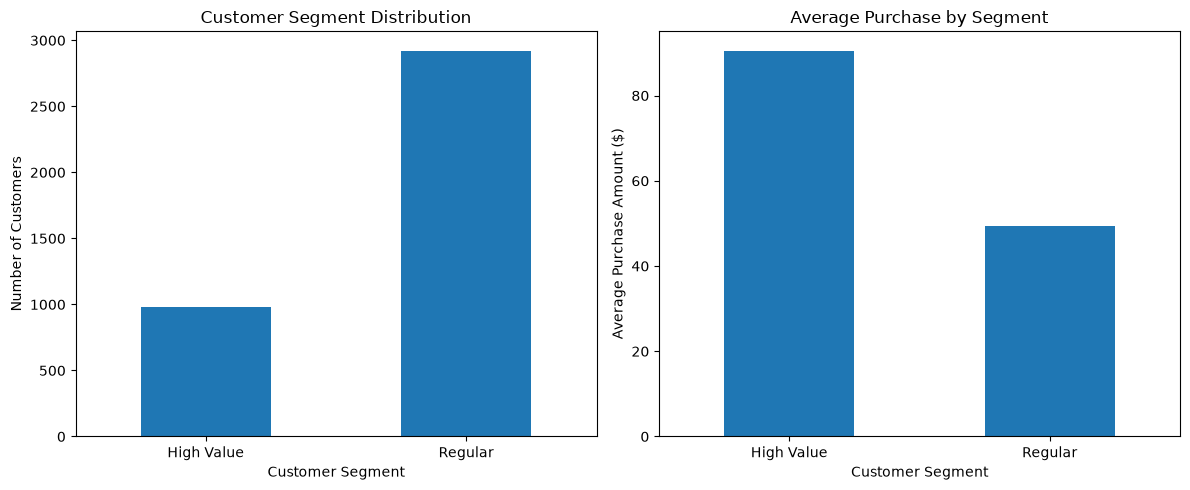

In [22]:

import matplotlib.pyplot as plt

# Create two comparison charts
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Chart 1: Number of customers
segment_analysis['total_customers'].plot(
    kind='bar',
    ax=axes[0],
    title='Customer Segment Distribution'
)
axes[0].set_xlabel('Customer Segment')
axes[0].set_ylabel('Number of Customers')
axes[0].tick_params(axis='x', rotation=0)

# Chart 2: Average purchase amount
segment_analysis['average_purchase'].plot(
    kind='bar',
    ax=axes[1],
    title='Average Purchase by Segment'
)
axes[1].set_xlabel('Customer Segment')
axes[1].set_ylabel('Average Purchase Amount ($)')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()


--- Subscription Status Analysis ---


,total_customers,avg_spend,total_revenue,avg_previous_purchases
subscription_status,,,,
No,2847,59.87,170436,25.08
Yes,1053,59.49,62645,26.08


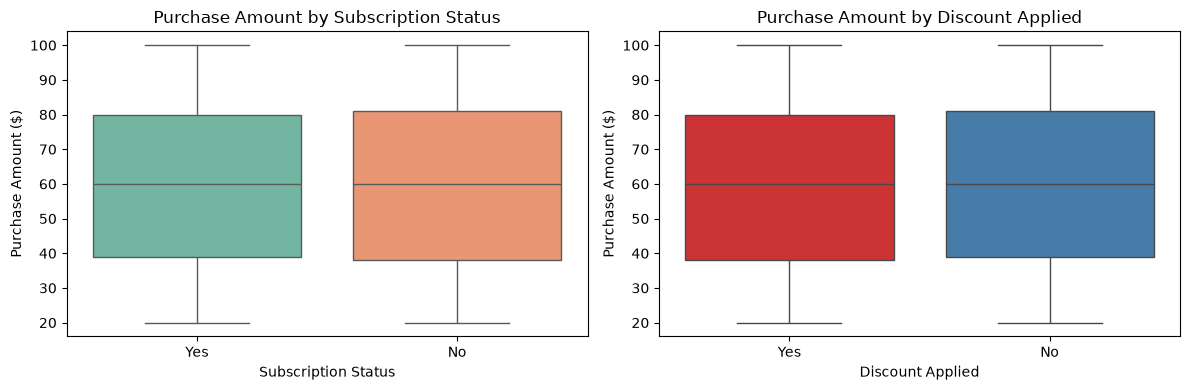


--- Statistical T-Test: Discount vs. Purchase Amount ---
Average Spend (With Discount): $59.28
Average Spend (Without Discount): $60.13
T-Statistic: -1.1122
Conclusion: No statistically significant difference in spending (p >= 0.05).


In [29]:
# --- 2 & 3. Customer Purchase Behavior & Spending Analysis ---
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Analyze spending by Subscription Status
sub_analysis = advanced_df.groupby('subscription_status').agg(
    total_customers=('customer_id', 'count'),
    avg_spend=('purchase_amount', 'mean'),
    total_revenue=('purchase_amount', 'sum'),
    avg_previous_purchases=('previous_purchases', 'mean')
).round(2)

print("--- Subscription Status Analysis ---")
display(sub_analysis)

# Visualizations: Spending by Subscription and Discount
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=advanced_df, x='subscription_status', y='purchase_amount', ax=axes[0], hue='subscription_status', palette='Set2', legend=False)
axes[0].set_title('Purchase Amount by Subscription Status')
axes[0].set_xlabel('Subscription Status')
axes[0].set_ylabel('Purchase Amount ($)')

sns.boxplot(data=advanced_df, x='discount_applied', y='purchase_amount', ax=axes[1], hue='discount_applied', palette='Set1', legend=False)
axes[1].set_title('Purchase Amount by Discount Applied')
axes[1].set_xlabel('Discount Applied')
axes[1].set_ylabel('Purchase Amount ($)')

plt.tight_layout()
plt.show()


# --- 4. Statistical Analysis (Manual T-Test using NumPy) ---
yes_disc = advanced_df[advanced_df['discount_applied'] == 'Yes']['purchase_amount']
no_disc = advanced_df[advanced_df['discount_applied'] == 'No']['purchase_amount']

# Calculate means, variances, and sample sizes
mean1, mean2 = yes_disc.mean(), no_disc.mean()
var1, var2 = yes_disc.var(ddof=1), no_disc.var(ddof=1)
n1, n2 = len(yes_disc), len(no_disc)

# Compute T-Statistic
t_stat = (mean1 - mean2) / np.sqrt((var1 / n1) + (var2 / n2))

print("\n--- Statistical T-Test: Discount vs. Purchase Amount ---")
print(f"Average Spend (With Discount): ${mean1:.2f}")
print(f"Average Spend (Without Discount): ${mean2:.2f}")
print(f"T-Statistic: {t_stat:.4f}")

# Check significance (For large samples > 1000, |t_stat| > 1.96 means p < 0.05)
if abs(t_stat) > 1.96:
    print("Conclusion: Statistically significant difference in spending (p < 0.05).")
else:
    print("Conclusion: No statistically significant difference in spending (p >= 0.05).")


###  Key Business Insights & Recommendations
* **Discount Strategy:** The T-test confirms there is no statistically significant difference in spending between customers who use discounts ($59.28) and those who don't ($60.13). **Recommendation:** Reduce blanket discounts and offer targeted discounts only to low-spending segments.
* **Subscription Impact:** Subscribers and non-subscribers have similar average spending (~$59), meaning the focus should be on increasing subscriber retention and frequency rather than just order value.
* **Customer Segmentation:** Clustering helps separate high-value loyal shoppers from occasional buyers for targeted marketing campaigns.
